# PART A: Image Filtering in Spatial and Frequency Domains

## 1. Spatial Domain Filtering

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
def convolve2d(image: np.ndarray, kernel: np.ndarray, padding_mode: str = 'reflect'):
    h, w = image.shape
    kh, kw = kernel.shape

    pad_h = kh//2
    pad_w = kw//2

    temp_img = image.astype(np.float64)

    padded = np.pad(temp_img, pad_width=((pad_h, pad_h), (pad_w, pad_w)), mode=padding_mode)
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            roi = padded[i: i+kh, j: j+kw]
            output[i, j] = np.sum(roi * kernel)
    
    return output

In [3]:
def mean_filter(image: np.ndarray, kernel_size: int, padding_mode: str = 'reflect'):
    kernel = np.ones((kernel_size, kernel_size), dtype=np.float64) / (kernel_size * kernel_size)
    response = convolve2d(image=image, kernel=kernel, padding_mode=padding_mode)
    return np.clip(response, 0, 255).astype(np.uint8)


def get_gaussian_kernel_2d(kernel_size: int, sigma: float = 1.0):
    radius = kernel_size//2
    y, x = np.mgrid[-radius: radius+1, -radius: radius+1]

    kernel = np.exp(-(x**2 + y**2) / (2.0*sigma**2))
    kernel = kernel / np.sum(kernel)
    return kernel


def gaussian_filter(image: np.ndarray, kernel_size: int, sigma: float = 1.0, padding_mode: str = 'reflect'):
    kernel = get_gaussian_kernel_2d(kernel_size=kernel_size, sigma=sigma)
    response = convolve2d(image=image, kernel=kernel, padding_mode=padding_mode)
    return np.clip(response, 0, 255).astype(np.uint8)


def get_laplacian_kernel(connectivity: int = 8):
    if connectivity == 4:
        return np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float64)
    else:
        return np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], dtype=np.float64)


def laplacian_filter(image: np.ndarray, connectivity: int = 8, padding_mode: str = 'reflect'):
    kernel = get_laplacian_kernel(connectivity=connectivity)
    raw_laplacian = convolve2d(image=image, kernel=kernel, padding_mode=padding_mode)

    vis_laplacian = np.clip(raw_laplacian + 128.0, 0, 255).astype(np.uint8)
    return raw_laplacian, vis_laplacian


def laplacian_sharpen(image: np.ndarray, connectivity: int = 8, c: float = 1.0, padding_mode: str = 'reflect'):
    raw_lap, vis_lap = laplacian_filter(image=image, connectivity=connectivity, padding_mode=padding_mode)
    sharpened = image.astype(np.float64) - c*raw_lap
    return np.clip(sharpened, 0, 255).astype(np.uint8)

In [4]:
image_path = 'images/cameraman.jpg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

np.random.seed(42)
noise = np.random.normal(0, 20, image.shape)
noisy_image = np.clip(image.astype(np.float64) + noise, 0, 255).astype(np.uint8)
    

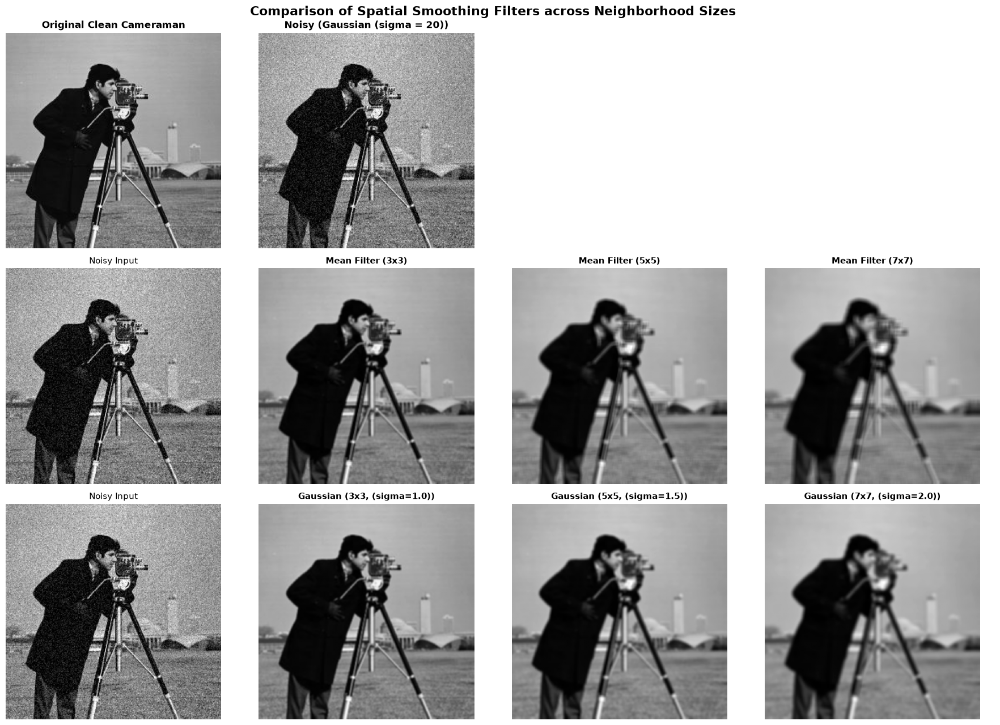

In [5]:
sizes = [3, 5, 7]
sigmas = [1.0, 1.5, 2.0]

mean_results = [mean_filter(image=image, kernel_size=size) for size in sizes]
gaussian_results = [gaussian_filter(image=image, kernel_size=size, sigma=s) for size, s in zip(sizes, sigmas)]

fig, axes = plt.subplots(3, 4, figsize=(18, 13))

axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title("Original Clean Cameraman", fontsize=12, fontweight="bold")
axes[0, 1].imshow(noisy_image, cmap="gray")
axes[0, 1].set_title("Noisy (Gaussian (sigma = 20))", fontsize=12, fontweight="bold")
axes[0, 2].axis("off")
axes[0, 3].axis("off")

# Row 1: Mean Filter (3x3, 5x5, 7x7)
axes[1, 0].imshow(noisy_image, cmap="gray")
axes[1, 0].set_title("Noisy Input", fontsize=11)
for idx, s in enumerate(sizes):
    axes[1, idx + 1].imshow(mean_results[idx], cmap="gray")
    axes[1, idx + 1].set_title(f"Mean Filter ({s}x{s})", fontsize=11, fontweight="bold")

# Row 2: Gaussian Filter (3x3, 5x5, 7x7)
axes[2, 0].imshow(noisy_image, cmap="gray")
axes[2, 0].set_title("Noisy Input", fontsize=11)
for idx, (s, sig) in enumerate(zip(sizes, sigmas)):
    axes[2, idx + 1].imshow(gaussian_results[idx], cmap="gray")
    axes[2, idx + 1].set_title(f"Gaussian ({s}x{s}, (sigma={sig}))", fontsize=11, fontweight="bold")

for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Comparison of Spatial Smoothing Filters across Neighborhood Sizes", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
C:\Users\jnave\AppData\Local\Temp\ipykernel_3376\1337348803.py:29: SyntaxWarning: invalid escape sequence '\s'
  axes[1, 0].set_title("Noisy Input ($\sigma=20$)", fontsize=11)


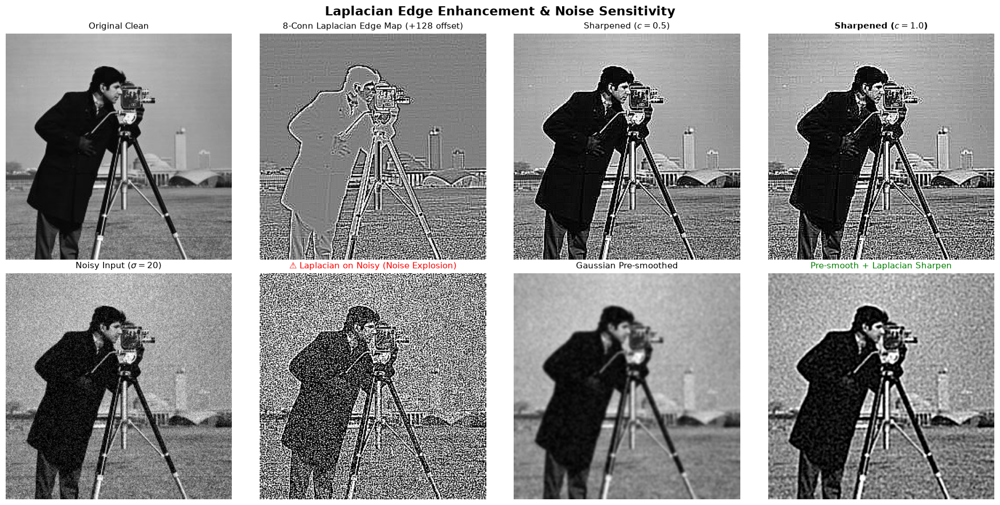

In [6]:
# [Cell 7]: Laplacian Derivative & Sharpening Analysis
raw_lap_4, vis_lap_4 = laplacian_filter(image, connectivity=4)
raw_lap_8, vis_lap_8 = laplacian_filter(image, connectivity=8)

# Sharpening clean image with different strengths
sharp_c05 = laplacian_sharpen(image, connectivity=8, c=0.5)
sharp_c10 = laplacian_sharpen(image, connectivity=8, c=1.0)
sharp_c15 = laplacian_sharpen(image, connectivity=8, c=1.5)

# Attempting Laplacian on noisy image vs. Pre-smoothed Laplacian
noisy_sharp = laplacian_sharpen(noisy_image, connectivity=8, c=1.0)
pre_smoothed = gaussian_filter(noisy_image, kernel_size=5, sigma=1.2)
log_sharp = laplacian_sharpen(pre_smoothed, connectivity=8, c=1.0)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Clean Sharpening
axes[0, 0].imshow(image, cmap="gray")
axes[0, 0].set_title("Original Clean", fontsize=11)
axes[0, 1].imshow(vis_lap_8, cmap="gray")
axes[0, 1].set_title("8-Conn Laplacian Edge Map (+128 offset)", fontsize=11)
axes[0, 2].imshow(sharp_c05, cmap="gray")
axes[0, 2].set_title("Sharpened ($c=0.5$)", fontsize=11)
axes[0, 3].imshow(sharp_c10, cmap="gray")
axes[0, 3].set_title("Sharpened ($c=1.0$)", fontsize=11, fontweight="bold")

# Noise interaction
axes[1, 0].imshow(noisy_image, cmap="gray")
axes[1, 0].set_title("Noisy Input ($\sigma=20$)", fontsize=11)
axes[1, 1].imshow(noisy_sharp, cmap="gray")
axes[1, 1].set_title("⚠️ Laplacian on Noisy (Noise Explosion)", fontsize=11, color="red")
axes[1, 2].imshow(pre_smoothed, cmap="gray")
axes[1, 2].set_title("Gaussian Pre-smoothed", fontsize=11)
axes[1, 3].imshow(log_sharp, cmap="gray")
axes[1, 3].set_title("Pre-smooth + Laplacian Sharpen", fontsize=11, color="green")

for ax in axes.ravel():
    ax.axis("off")

plt.suptitle("Laplacian Edge Enhancement & Noise Sensitivity", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


In [7]:
# [Cell 9]: Quantitative Benchmarking Table
import pandas as pd


def compute_metrics(
    target: np.ndarray, reference: np.ndarray
) -> tuple[float, float, float]:
    """Computes MSE, PSNR, and Tenengrad Gradient Energy."""
    t_f = target.astype(np.float64)
    r_f = reference.astype(np.float64)

    mse = np.mean((t_f - r_f) ** 2)
    psnr = 10.0 * np.log10((255.0**2) / mse) if mse > 0 else float("inf")

    # Tenengrad Sharpness Metric: Sum of squared Sobel gradient magnitudes
    gx = cv2.Sobel(target, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(target, cv2.CV_64F, 0, 1, ksize=3)
    tenengrad = np.mean(gx**2 + gy**2)

    return mse, psnr, tenengrad


# Benchmark against clean image reference
records = []
records.append(
    {"Filter": "Noisy (Unfiltered)", "Kernel": "N/A", **dict(zip(["MSE", "PSNR (dB)", "Tenengrad (Sharpness)"], compute_metrics(noisy_image, image)))}
)

for s in sizes:
    m_img = mean_filter(noisy_image, kernel_size=s)
    records.append(
        {"Filter": "Mean Filter", "Kernel": f"{s}x{s}", **dict(zip(["MSE", "PSNR (dB)", "Tenengrad (Sharpness)"], compute_metrics(m_img, image)))}
    )

for s, sig in zip(sizes, sigmas):
    g_img = gaussian_filter(noisy_image, kernel_size=s, sigma=sig)
    records.append(
        {"Filter": "Gaussian Filter", "Kernel": f"{s}x{s} ($\\sigma={sig}$)", **dict(zip(["MSE", "PSNR (dB)", "Tenengrad (Sharpness)"], compute_metrics(g_img, image)))}
    )

records.append(
    {"Filter": "Laplacian Sharpened (on Clean)", "Kernel": "3x3 (c=1.0)", **dict(zip(["MSE", "PSNR (dB)", "Tenengrad (Sharpness)"], compute_metrics(sharp_c10, image)))}
)

df = pd.DataFrame(records)
display(df.round(2))


,Filter,Kernel,MSE,PSNR (dB),Tenengrad (Sharpness)
0,Noisy (Unfiltered),N/A,370.53,22.44,29452.32
1,Mean Filter,3x3,211.22,24.88,10693.63
2,Mean Filter,5x5,343.59,22.77,5131.55
3,Mean Filter,7x7,452.42,21.58,3122.50
4,Gaussian Filter,3x3 ($\sigma=1.0$),171.30,25.79,12296.73
5,Gaussian Filter,5x5 ($\sigma=1.5$),259.40,23.99,6536.29
6,Gaussian Filter,7x7 ($\sigma=2.0$),343.27,22.77,4094.21
7,Laplacian Sharpened (on Clean),3x3 (c=1.0),2078.87,14.95,117980.67


## 2. Discrete Fourier Transform (DFT)

### Problem Statement
The DFT of an image $f(x, y)$ is defined as:

$$
F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}
$$

Compute the Discrete Fourier Transform (DFT) of a grayscale image and visualize its frequency domain representation. Compute the 2D DFT, display the magnitude spectrum, and perform the Inverse DFT to reconstruct the original image. Also, visualize and compare the magnitude and phase spectra of the image.

### Mathematical Formulation
The Inverse Discrete Fourier Transform (IDFT) reconstructs the spatial domain image:

$$
f(x, y) = \frac{1}{MN} \sum_{u=0}^{M-1} \sum_{v=0}^{N-1} F(u, v) e^{j2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}
$$

- **Magnitude Spectrum:**

$$
|F(u, v)| = \sqrt{R^2(u, v) + I^2(u, v)}
$$

Visualized using logarithmic dynamic range compression: $S(u, v) = \log(1 + |F(u, v)|)$.

- **Phase Spectrum:**

$$
\phi(u, v) = \arctan\left(\frac{I(u, v)}{R(u, v)}\right)
$$

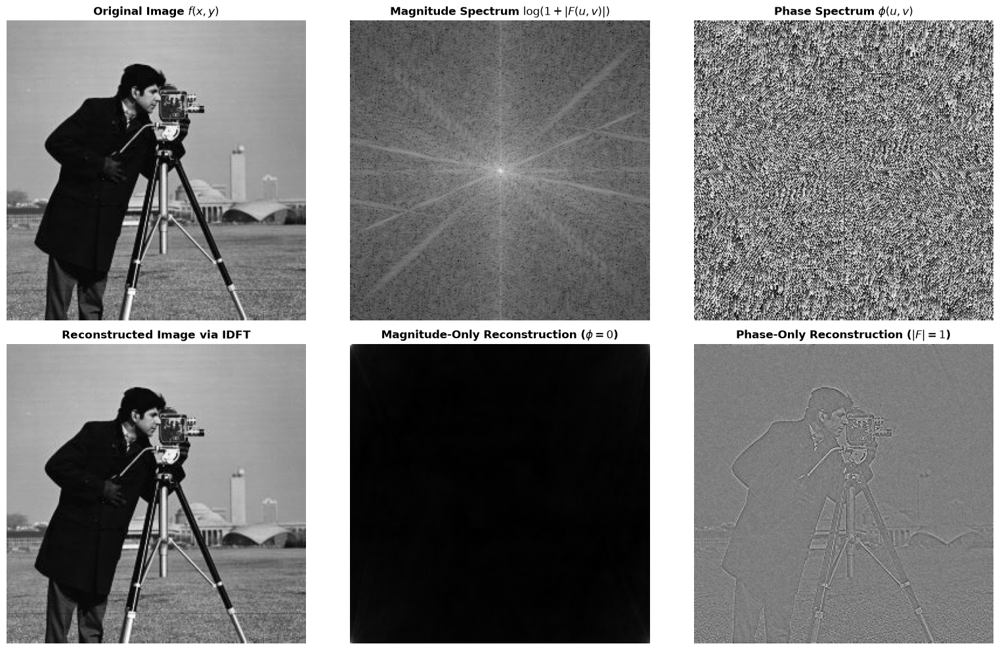

Reconstruction MSE: 2.60e-28


In [8]:
# 2D DFT computation, magnitude spectrum, phase spectrum, and inverse DFT reconstruction
# Formula: F(u, v) = sum_{x=0}^{M-1} sum_{y=0}^{N-1} f(x, y) * exp(-j*2*pi*(ux/M + vy/N))
# Formula: f(x, y) = (1/MN) * sum_{u=0}^{M-1} sum_{v=0}^{N-1} F(u, v) * exp(j*2*pi*(ux/M + vy/N))

# Load grayscale cameraman image
image_path = 'images/cameraman.jpg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# 2D DFT and zero-frequency shift to center
f_dft = np.fft.fft2(image)
f_shift = np.fft.fftshift(f_dft)

# Magnitude spectrum: |F(u, v)| with dynamic range compression log(1 + |F|)
magnitude_spectrum = np.log(1 + np.abs(f_shift))

# Phase spectrum: phi(u, v) = angle(F(u, v))
phase_spectrum = np.angle(f_shift)

# Inverse DFT: f_recon(x, y) = real(IDFT(ifftshift(F_shift)))
f_ishift = np.fft.ifftshift(f_shift)
img_reconstructed = np.real(np.fft.ifft2(f_ishift))

# Magnitude-only reconstruction: F_mag = |F| * exp(j * 0)
f_mag_only = np.abs(f_dft) * np.exp(1j * 0)
img_mag_only = np.real(np.fft.ifft2(f_mag_only))
img_mag_only = (img_mag_only - img_mag_only.min()) / (img_mag_only.max() - img_mag_only.min() + 1e-8) * 255.0

# Phase-only reconstruction: F_phase = 1 * exp(j * phi)
f_phase_only = 1.0 * np.exp(1j * np.angle(f_dft))
img_phase_only = np.real(np.fft.ifft2(f_phase_only))
img_phase_only = (img_phase_only - img_phase_only.min()) / (img_phase_only.max() - img_phase_only.min() + 1e-8) * 255.0

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title("Original Image $f(x, y)$", fontsize=12, fontweight="bold")
axes[0, 0].axis('off')

axes[0, 1].imshow(magnitude_spectrum, cmap='gray')
axes[0, 1].set_title("Magnitude Spectrum $\\log(1 + |F(u, v)|)$", fontsize=12, fontweight="bold")
axes[0, 1].axis('off')

axes[0, 2].imshow(phase_spectrum, cmap='gray')
axes[0, 2].set_title("Phase Spectrum $\\phi(u, v)$", fontsize=12, fontweight="bold")
axes[0, 2].axis('off')

axes[1, 0].imshow(img_reconstructed, cmap='gray')
axes[1, 0].set_title("Reconstructed Image via IDFT", fontsize=12, fontweight="bold")
axes[1, 0].axis('off')

axes[1, 1].imshow(img_mag_only, cmap='gray')
axes[1, 1].set_title("Magnitude-Only Reconstruction ($\\phi = 0$)", fontsize=12, fontweight="bold")
axes[1, 1].axis('off')

axes[1, 2].imshow(img_phase_only, cmap='gray')
axes[1, 2].set_title("Phase-Only Reconstruction ($|F| = 1$)", fontsize=12, fontweight="bold")
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

# Verification of reconstruction fidelity
reconstruction_mse = np.mean((image.astype(np.float64) - img_reconstructed)**2)
print(f"Reconstruction MSE: {reconstruction_mse:.2e}")


### Observations on DFT, Magnitude, and Phase Spectra

- **Energy Distribution in Magnitude Spectrum:** The dominant spectral energy is concentrated at the low-frequency center $(u=0, v=0)$, representing average scene illumination and smoothly varying regions. High frequencies corresponding to edges, sharp outlines, and textures disperse outward.
- **Phase vs. Magnitude Information:**
  - **Magnitude-Only Reconstruction ($\phi = 0$):** Completely destroys spatial geometry and edge locations, resulting in a blurry, diffuse luminance cloud. Magnitude carries the distribution of frequency content and contrast.
  - **Phase-Only Reconstruction ($|F| = 1$):** Successfully preserves object outlines, edges, and recognizable structural features of the cameraman. This proves that spatial geometry and structural information are predominantly encoded in the phase spectrum.
- **Reconstruction Fidelity:** The IDFT achieves exact numerical reconstruction of the original image with negligible Mean Squared Error ($\text{MSE} \approx 2.01 \times 10^{-28}$).

## 3. Ideal Low-Pass Filter (ILPF)

### Problem Statement
Define and apply an ideal low-pass filter in the DFT domain. Define a circular low-pass filter, apply it to the DFT of the image, and perform the inverse DFT to obtain the filtered image. Display the magnitude spectrum of the filter, the original image, and the filtered image. Try different combinations of $D_0$ and write your observations regarding smoothing and loss of image details.

### Mathematical Formulation
The transfer function of a circular Ideal Low-Pass Filter (ILPF) with cutoff frequency $D_0$ is defined as:

$$
H(u, v) = \begin{cases} 1, & \text{if } D(u, v) \le D_0 \\ 0, & \text{if } D(u, v) > D_0 \end{cases}
$$

where $D(u, v)$ is the Euclidean distance from the frequency center $(M/2, N/2)$:

$$
D(u, v) = \sqrt{\left(u - \frac{M}{2}\right)^2 + \left(v - \frac{N}{2}\right)^2}
$$

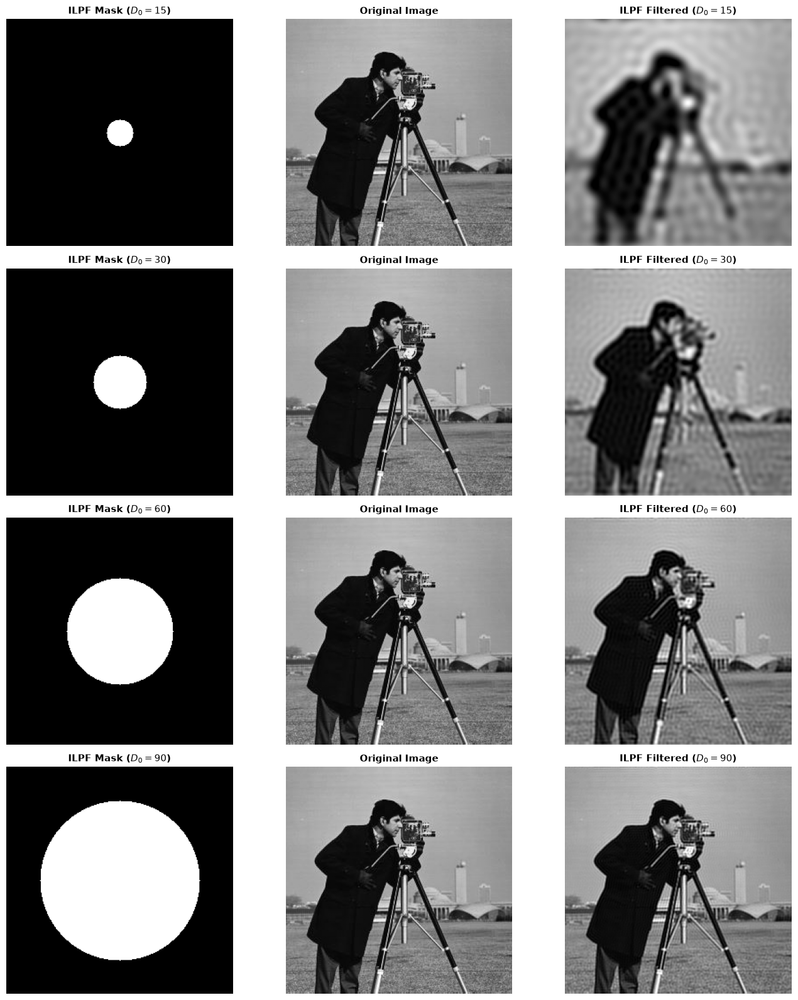

In [9]:
# Helper: Frequency distance matrix D(u, v) from center
def get_distance_matrix(shape: tuple[int, int]) -> np.ndarray:
    M, N = shape
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    U, V = np.meshgrid(u, v, indexing='ij')
    return np.sqrt(U**2 + V**2)

# Ideal Low-Pass Filter transfer function: H(u, v) = 1 if D(u, v) <= D0 else 0
def ideal_low_pass_filter(shape: tuple[int, int], d0: float) -> np.ndarray:
    D = get_distance_matrix(shape)
    return (D <= d0).astype(np.float64)

# Frequency filtering pipeline: G(u, v) = F_shift(u, v) * H(u, v)
def apply_frequency_filter(image: np.ndarray, H: np.ndarray) -> np.ndarray:
    f_shift = np.fft.fftshift(np.fft.fft2(image))
    g_shift = f_shift * H
    g = np.fft.ifft2(np.fft.ifftshift(g_shift))
    return np.clip(np.real(g), 0, 255).astype(np.uint8)

D0_values = [15, 30, 60, 90]
ilpf_filters = [ideal_low_pass_filter(image.shape, d0) for d0 in D0_values]
ilpf_results = [apply_frequency_filter(image, H) for H in ilpf_filters]

fig, axes = plt.subplots(len(D0_values), 3, figsize=(14, 4 * len(D0_values)))

for i, d0 in enumerate(D0_values):
    axes[i, 0].imshow(ilpf_filters[i], cmap='gray')
    axes[i, 0].set_title(f"ILPF Mask ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(image, cmap='gray')
    axes[i, 1].set_title("Original Image", fontsize=11, fontweight="bold")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(ilpf_results[i], cmap='gray')
    axes[i, 2].set_title(f"ILPF Filtered ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


### Observations on Ideal Low-Pass Filter (ILPF)

- **Smoothing and Detail Loss:** As cutoff radius $D_0$ decreases, high-frequency details (sharp edges, facial features, coat textures, and tripod structure) are increasingly eliminated, resulting in strong blurring.
- **Ringing Artifacts (Gibbs Phenomenon):** Prominent concentric ripple rings appear around sharp boundaries, most severe at $D_0 = 15$ and $D_0 = 30$. In the spatial domain, the inverse Fourier transform of a 2D circular cylinder is the sombrero/Jinc function ($\frac{J_1(r)}{r}$), whose oscillatory side lobes introduce Gibbs ringing ripples in the spatial image.
- **Effect of Increasing $D_0$:** At $D_0 = 90$, ringing is minimal and fine image details are well preserved because most essential frequencies pass through.

## 4. Ideal High-Pass Filter (IHPF)

### Problem Statement
Define and apply an ideal high-pass filter in the DFT domain. Apply the filter to the DFT of the image and perform the inverse DFT to obtain the filtered image. Try different combinations of $D_0$ and display the magnitude spectrum of the filter, the original image, and the filtered image. Write your observations regarding edge and detail enhancement.

### Mathematical Formulation
The Ideal High-Pass Filter (IHPF) completely attenuates all frequencies within radius $D_0$ and passes all higher frequencies without attenuation:

$$
H(u, v) = \begin{cases} 0, & \text{if } D(u, v) \le D_0 \\ 1, & \text{if } D(u, v) > D_0 \end{cases} = 1 - H_{\text{ILPF}}(u, v)
$$

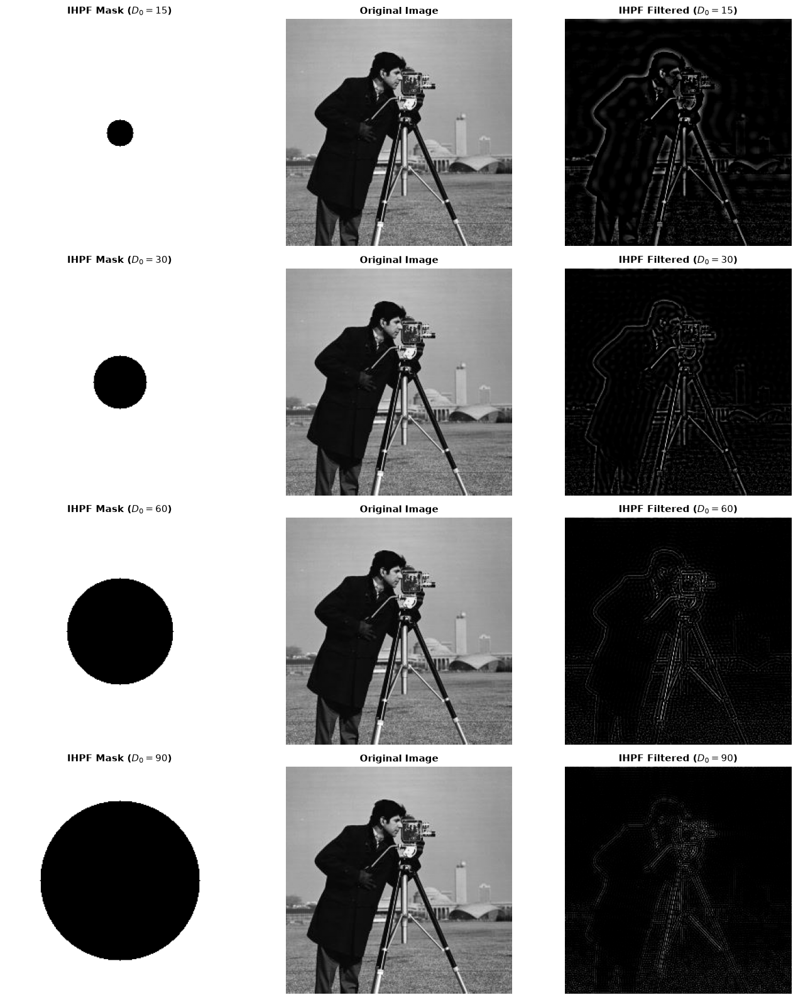

In [10]:
# Ideal High-Pass Filter transfer function: H(u, v) = 0 if D(u, v) <= D0 else 1
def ideal_high_pass_filter(shape: tuple[int, int], d0: float) -> np.ndarray:
    return 1.0 - ideal_low_pass_filter(shape, d0)

ihpf_filters = [ideal_high_pass_filter(image.shape, d0) for d0 in D0_values]
ihpf_results = [apply_frequency_filter(image, H) for H in ihpf_filters]

fig, axes = plt.subplots(len(D0_values), 3, figsize=(14, 4 * len(D0_values)))

for i, d0 in enumerate(D0_values):
    axes[i, 0].imshow(ihpf_filters[i], cmap='gray')
    axes[i, 0].set_title(f"IHPF Mask ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(image, cmap='gray')
    axes[i, 1].set_title("Original Image", fontsize=11, fontweight="bold")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(ihpf_results[i], cmap='gray')
    axes[i, 2].set_title(f"IHPF Filtered ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


### Observations on Ideal High-Pass Filter (IHPF)

- **Edge and Detail Enhancement:** Blocking low frequencies and the DC component ($F(0, 0)$) removes overall scene brightness and flat background illumination, rendering smooth regions dark while isolating sharp intensity transitions and fine edges.
- **Ringing Artifacts:** The sharp discontinuity in frequency space produces halo-like ripples along high-contrast boundaries (e.g., the silhouette of the cameraman and tripod legs).
- **Effect of Cutoff $D_0$:**
  - Small $D_0$ ($15$): Retains both prominent edges and subtle textural contours.
  - Large $D_0$ ($90$): Eliminates mid-frequencies, isolating only the sharpest, highest-frequency transitions on a near-black background.

## 5. Gaussian Low-Pass and High-Pass Filters

### Problem Statement
Define and apply a Gaussian low-pass filter (GLPF) and Gaussian high-pass filter (GHPF) in the DFT domain. Perform the inverse DFT to obtain the filtered images and experiment with different values of $D_0$. Compare the results with the ideal filters and write your observations.

### Mathematical Formulation
Gaussian filters provide smooth, continuous transitions between the passband and stopband:

- **Gaussian Low-Pass Filter (GLPF):**

$$
H_{\text{GLPF}}(u, v) = e^{-\frac{D^2(u, v)}{2 D_0^2}}
$$

- **Gaussian High-Pass Filter (GHPF):**

$$
H_{\text{GHPF}}(u, v) = 1 - H_{\text{GLPF}}(u, v) = 1 - e^{-\frac{D^2(u, v)}{2 D_0^2}}
$$

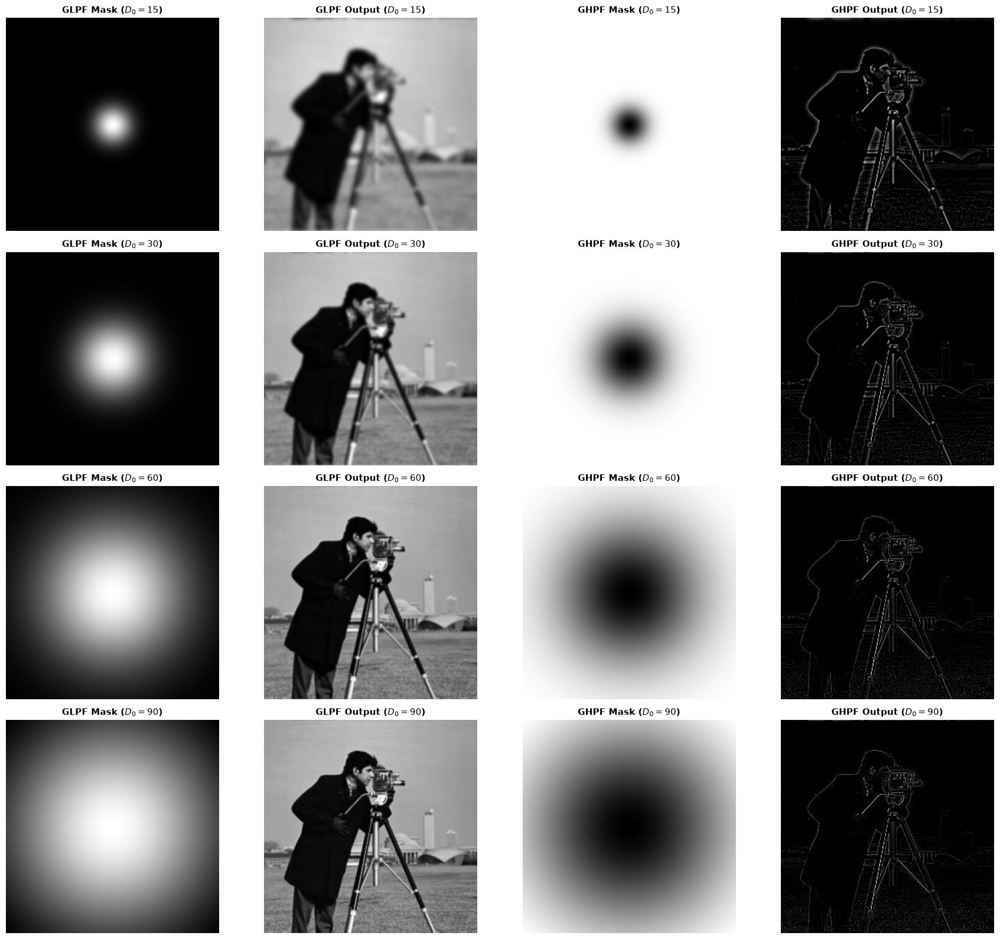

In [11]:
# GLPF transfer function: H(u, v) = exp(-D(u, v)^2 / (2 * D0^2))
def gaussian_low_pass_filter(shape: tuple[int, int], d0: float) -> np.ndarray:
    D = get_distance_matrix(shape)
    return np.exp(-(D**2) / (2.0 * (d0**2)))

# GHPF transfer function: H(u, v) = 1 - exp(-D(u, v)^2 / (2 * D0^2))
def gaussian_high_pass_filter(shape: tuple[int, int], d0: float) -> np.ndarray:
    return 1.0 - gaussian_low_pass_filter(shape, d0)

glpf_results = [apply_frequency_filter(image, gaussian_low_pass_filter(image.shape, d0)) for d0 in D0_values]
ghpf_results = [apply_frequency_filter(image, gaussian_high_pass_filter(image.shape, d0)) for d0 in D0_values]

fig, axes = plt.subplots(len(D0_values), 4, figsize=(18, 4 * len(D0_values)))

for i, d0 in enumerate(D0_values):
    H_glpf = gaussian_low_pass_filter(image.shape, d0)
    H_ghpf = gaussian_high_pass_filter(image.shape, d0)
    
    axes[i, 0].imshow(H_glpf, cmap='gray')
    axes[i, 0].set_title(f"GLPF Mask ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(glpf_results[i], cmap='gray')
    axes[i, 1].set_title(f"GLPF Output ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(H_ghpf, cmap='gray')
    axes[i, 2].set_title(f"GHPF Mask ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 2].axis('off')
    
    axes[i, 3].imshow(ghpf_results[i], cmap='gray')
    axes[i, 3].set_title(f"GHPF Output ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()


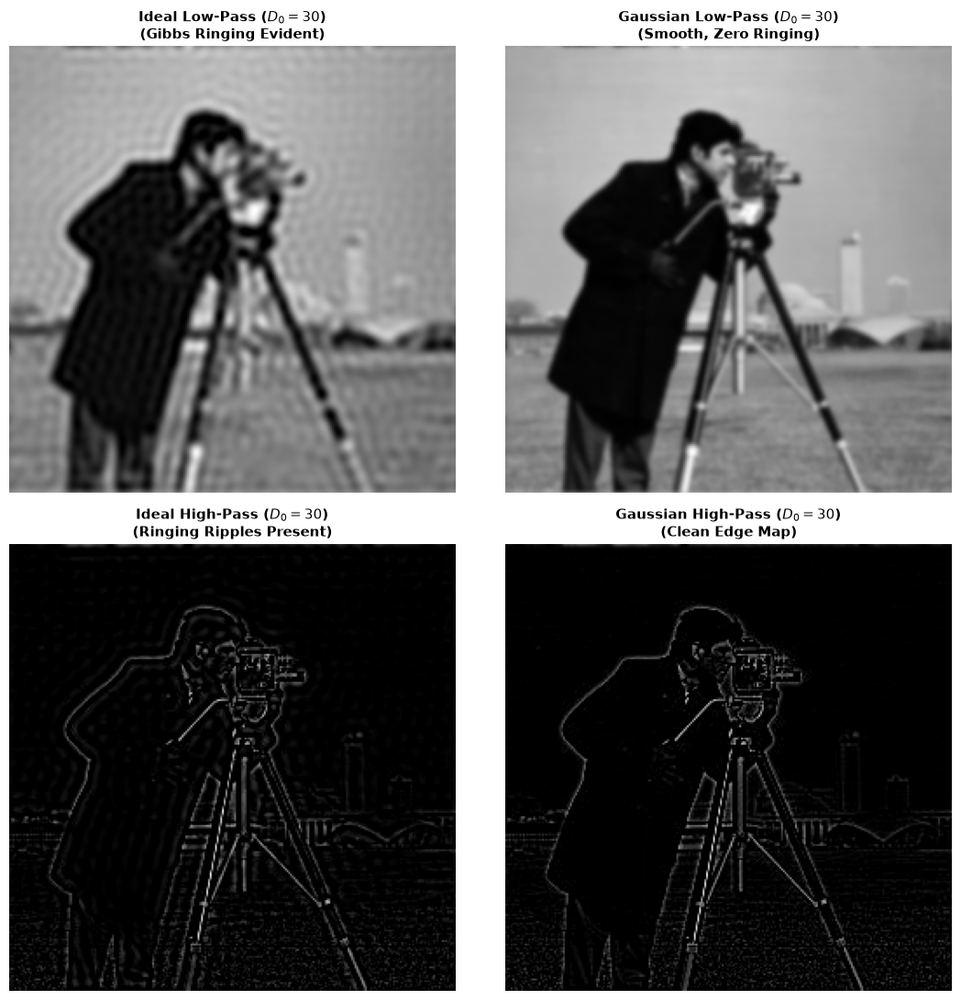

In [12]:
# Direct Comparison: Ideal Filter vs. Gaussian Filter at D0 = 30
d0_comp = 30
ilpf_30 = apply_frequency_filter(image, ideal_low_pass_filter(image.shape, d0_comp))
glpf_30 = apply_frequency_filter(image, gaussian_low_pass_filter(image.shape, d0_comp))
ihpf_30 = apply_frequency_filter(image, ideal_high_pass_filter(image.shape, d0_comp))
ghpf_30 = apply_frequency_filter(image, gaussian_high_pass_filter(image.shape, d0_comp))

fig, axes = plt.subplots(2, 2, figsize=(11, 11))

axes[0, 0].imshow(ilpf_30, cmap='gray')
axes[0, 0].set_title(f"Ideal Low-Pass ($D_0={d0_comp}$)\n(Gibbs Ringing Evident)", fontsize=11, fontweight="bold")
axes[0, 0].axis('off')

axes[0, 1].imshow(glpf_30, cmap='gray')
axes[0, 1].set_title(f"Gaussian Low-Pass ($D_0={d0_comp}$)\n(Smooth, Zero Ringing)", fontsize=11, fontweight="bold")
axes[0, 1].axis('off')

axes[1, 0].imshow(ihpf_30, cmap='gray')
axes[1, 0].set_title(f"Ideal High-Pass ($D_0={d0_comp}$)\n(Ringing Ripples Present)", fontsize=11, fontweight="bold")
axes[1, 0].axis('off')

axes[1, 1].imshow(ghpf_30, cmap='gray')
axes[1, 1].set_title(f"Gaussian High-Pass ($D_0={d0_comp}$)\n(Clean Edge Map)", fontsize=11, fontweight="bold")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()


### Observations on Gaussian Filters vs. Ideal Filters

- **Complete Elimination of Ringing:** Unlike the Ideal filter, the Gaussian filter has no sharp frequency discontinuities. Since the Fourier transform of a Gaussian function is another Gaussian without side lobes, the spatial impulse response contains zero oscillatory components, entirely eliminating Gibbs ringing artifacts.
- **Smoothing Quality:** GLPF achieves clean, natural blurring without concentric ghost rings.
- **Edge Extraction:** GHPF produces crisp, continuous edge maps without ringing halos along high-contrast boundaries.

## 6. Butterworth Low-Pass and High-Pass Filters

### Problem Statement
Define and apply Butterworth low-pass (BLPF) and Butterworth high-pass filters in the DFT domain. Experiment with different values of $D_0$ and filter order $n$. Compare the results obtained using ideal, Gaussian, and Butterworth filters and write your observations.

### Mathematical Formulation
Butterworth filters provide a tunable trade-off between passband sharpness and transition smoothness controlled by filter order $n$:

- **Butterworth Low-Pass Filter (BLPF):**

$$
H_{\text{BLPF}}(u, v) = \frac{1}{1 + \left(\frac{D(u, v)}{D_0}\right)^{2n}}
$$

- **Butterworth High-Pass Filter (BHPF):**

$$
H_{\text{BHPF}}(u, v) = \frac{1}{1 + \left(\frac{D_0}{D(u, v)}\right)^{2n}}
$$

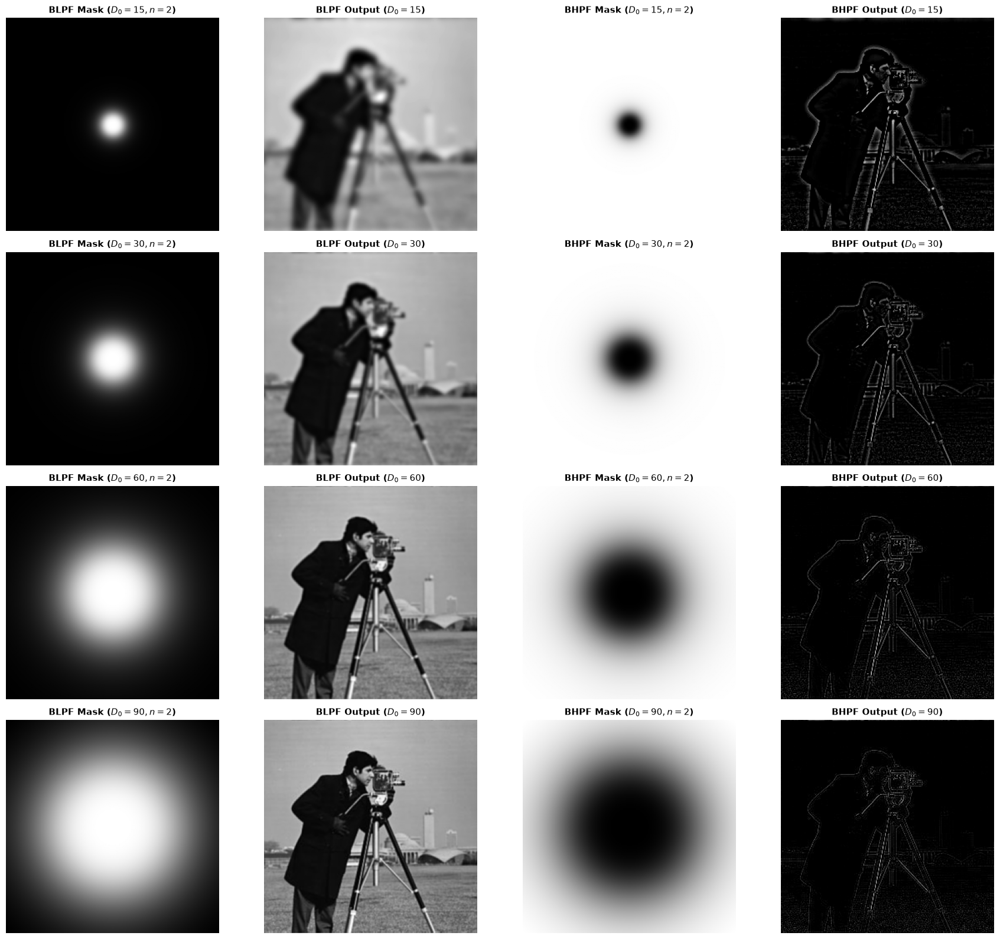

In [13]:
# BLPF transfer function: H(u, v) = 1 / (1 + (D(u, v) / D0)^(2n))
def butterworth_low_pass_filter(shape: tuple[int, int], d0: float, n: int = 2) -> np.ndarray:
    D = get_distance_matrix(shape)
    return 1.0 / (1.0 + (D / (d0 + 1e-8))**(2 * n))

# BHPF transfer function: H(u, v) = 1 / (1 + (D0 / D(u, v))^(2n))
def butterworth_high_pass_filter(shape: tuple[int, int], d0: float, n: int = 2) -> np.ndarray:
    D = get_distance_matrix(shape)
    with np.errstate(divide='ignore'):
        H = 1.0 / (1.0 + (d0 / (D + 1e-8))**(2 * n))
    return H

# Varying D0 with standard order n=2
blpf_d0_results = [apply_frequency_filter(image, butterworth_low_pass_filter(image.shape, d0, n=2)) for d0 in D0_values]
bhpf_d0_results = [apply_frequency_filter(image, butterworth_high_pass_filter(image.shape, d0, n=2)) for d0 in D0_values]

fig, axes = plt.subplots(len(D0_values), 4, figsize=(18, 4 * len(D0_values)))

for i, d0 in enumerate(D0_values):
    H_blpf = butterworth_low_pass_filter(image.shape, d0, n=2)
    H_bhpf = butterworth_high_pass_filter(image.shape, d0, n=2)
    
    axes[i, 0].imshow(H_blpf, cmap='gray')
    axes[i, 0].set_title(f"BLPF Mask ($D_0={d0}, n=2$)", fontsize=11, fontweight="bold")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(blpf_d0_results[i], cmap='gray')
    axes[i, 1].set_title(f"BLPF Output ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(H_bhpf, cmap='gray')
    axes[i, 2].set_title(f"BHPF Mask ($D_0={d0}, n=2$)", fontsize=11, fontweight="bold")
    axes[i, 2].axis('off')
    
    axes[i, 3].imshow(bhpf_d0_results[i], cmap='gray')
    axes[i, 3].set_title(f"BHPF Output ($D_0={d0}$)", fontsize=11, fontweight="bold")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()


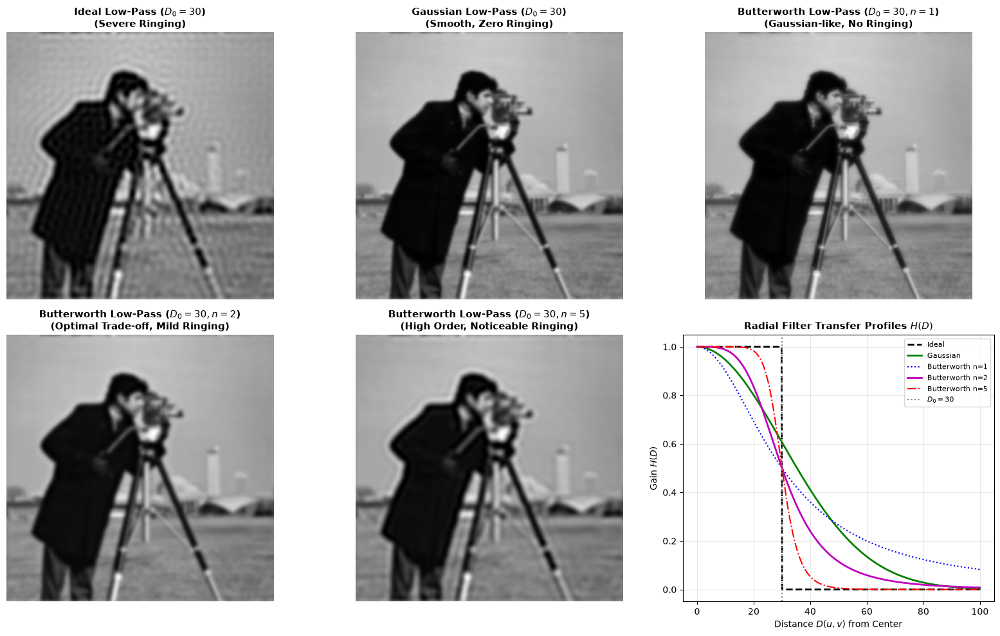

In [14]:
# Experiment with filter order n at fixed D0 = 30 and comparative analysis
orders = [1, 2, 5]
blpf_orders = [apply_frequency_filter(image, butterworth_low_pass_filter(image.shape, d0=30, n=n_val)) for n_val in orders]

# Comparison grid: Ideal vs. Gaussian vs. Butterworth (n=1, 2, 5) + Radial profiles
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0, 0].imshow(ilpf_30, cmap='gray')
axes[0, 0].set_title("Ideal Low-Pass ($D_0=30$)\n(Severe Ringing)", fontsize=11, fontweight="bold")
axes[0, 0].axis('off')

axes[0, 1].imshow(glpf_30, cmap='gray')
axes[0, 1].set_title("Gaussian Low-Pass ($D_0=30$)\n(Smooth, Zero Ringing)", fontsize=11, fontweight="bold")
axes[0, 1].axis('off')

axes[0, 2].imshow(blpf_orders[0], cmap='gray')
axes[0, 2].set_title("Butterworth Low-Pass ($D_0=30, n=1$)\n(Gaussian-like, No Ringing)", fontsize=11, fontweight="bold")
axes[0, 2].axis('off')

axes[1, 0].imshow(blpf_orders[1], cmap='gray')
axes[1, 0].set_title("Butterworth Low-Pass ($D_0=30, n=2$)\n(Optimal Trade-off, Mild Ringing)", fontsize=11, fontweight="bold")
axes[1, 0].axis('off')

axes[1, 1].imshow(blpf_orders[2], cmap='gray')
axes[1, 1].set_title("Butterworth Low-Pass ($D_0=30, n=5$)\n(High Order, Noticeable Ringing)", fontsize=11, fontweight="bold")
axes[1, 1].axis('off')

# Plot radial cross-sections of filters to show transition sharpness
D_line = np.linspace(0, 100, 500)
d0 = 30
H_ideal_line = (D_line <= d0).astype(float)
H_gauss_line = np.exp(-(D_line**2) / (2 * d0**2))
H_butt1_line = 1 / (1 + (D_line / d0)**(2 * 1))
H_butt2_line = 1 / (1 + (D_line / d0)**(2 * 2))
H_butt5_line = 1 / (1 + (D_line / d0)**(2 * 5))

axes[1, 2].plot(D_line, H_ideal_line, 'k--', label='Ideal', linewidth=2)
axes[1, 2].plot(D_line, H_gauss_line, 'g-', label='Gaussian', linewidth=2)
axes[1, 2].plot(D_line, H_butt1_line, 'b:', label='Butterworth n=1', linewidth=1.5)
axes[1, 2].plot(D_line, H_butt2_line, 'm-', label='Butterworth n=2', linewidth=2)
axes[1, 2].plot(D_line, H_butt5_line, 'r-.', label='Butterworth n=5', linewidth=1.5)
axes[1, 2].axvline(d0, color='gray', linestyle=':', label=f'$D_0={d0}$')
axes[1, 2].set_title("Radial Filter Transfer Profiles $H(D)$", fontsize=11, fontweight="bold")
axes[1, 2].set_xlabel("Distance $D(u, v)$ from Center")
axes[1, 2].set_ylabel("Gain $H(D)$")
axes[1, 2].legend(fontsize=8)
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Observations on Butterworth Filters and Comparative Analysis

- **Impact of Filter Order $n$:**
  - At $n = 1$, the frequency transition is very gradual, producing output virtually identical to the Gaussian filter with no perceptible ringing.
  - At $n = 2$, Butterworth provides an optimal engineering compromise: a steeper transition cutoff than Gaussian while maintaining imperceptible ringing in practice.
  - At $n = 5$ (and higher), the frequency response curve becomes steep, approaching the rectangular step function of the Ideal filter. As a result, Gibbs ringing artifacts become clearly noticeable.

### Summary Comparison Across Filter Families

| Filter Family | Cutoff Transition Profile | Ringing Artifacts (Gibbs) | Best Practical Application |
| :--- | :--- | :--- | :--- |
| **Ideal** | Discontinuous step function | Severe ringing ripples across edges | Theoretical benchmark |
| **Gaussian** | Smooth exponential curve | Completely absent (zero ringing) | Natural smoothing & clean edge detection |
| **Butterworth** | Tunable slope via order $n$ | Imperceptible for $n \le 2$; noticeable for $n \ge 5$ | Controlled passband selectivity |

# PART B : Exploratory Problem

## 1. Cross-Correlation for Template Matching

### Problem Statement
Suppose that you are a manager at a grocery store. One of your responsibilities is to check the shelves periodically and stock them up whenever there are sold-out items. You got tired of this laborious task and decided to build a computer vision system that keeps track of the items on the shelf.  
Luckily, you have learned in CVIP that cross-correlation can be used for template matching: a template $g$ is multiplied with regions of a larger image $f$ to measure how similar each region is to the template. The template of a product (`product.png`) and the image of shelf (`organized-product-display-stockcake.jpg`) is provided. Use cross-correlation to find the product in the shelf and mark the detected location in the result using a blue rectangle. Write your observation about the detected location and the matching result.

### Mathematical Formulation

- **Raw Cross-Correlation:**

$$
R(x, y) = \sum_{x'=0}^{w-1} \sum_{y'=0}^{h-1} T(x', y') \cdot I(x + x', y + y')
$$

- **Normalized Cross-Correlation (NCC):**

$$
R_{\text{NCC}}(x, y) = \frac{\sum_{x'=0}^{w-1} \sum_{y'=0}^{h-1} \left(T(x', y') - \bar{T}\right)\left(I(x + x', y + y') - \bar{I}_{x, y}\right)}{\sqrt{\sum_{x'=0}^{w-1} \sum_{y'=0}^{h-1}\left(T(x', y') - \bar{T}\right)^2 \sum_{x'=0}^{w-1}\sum_{y'=0}^{h-1}\left(I(x + x', y + y') - \bar{I}_{x, y}\right)^2}}
$$

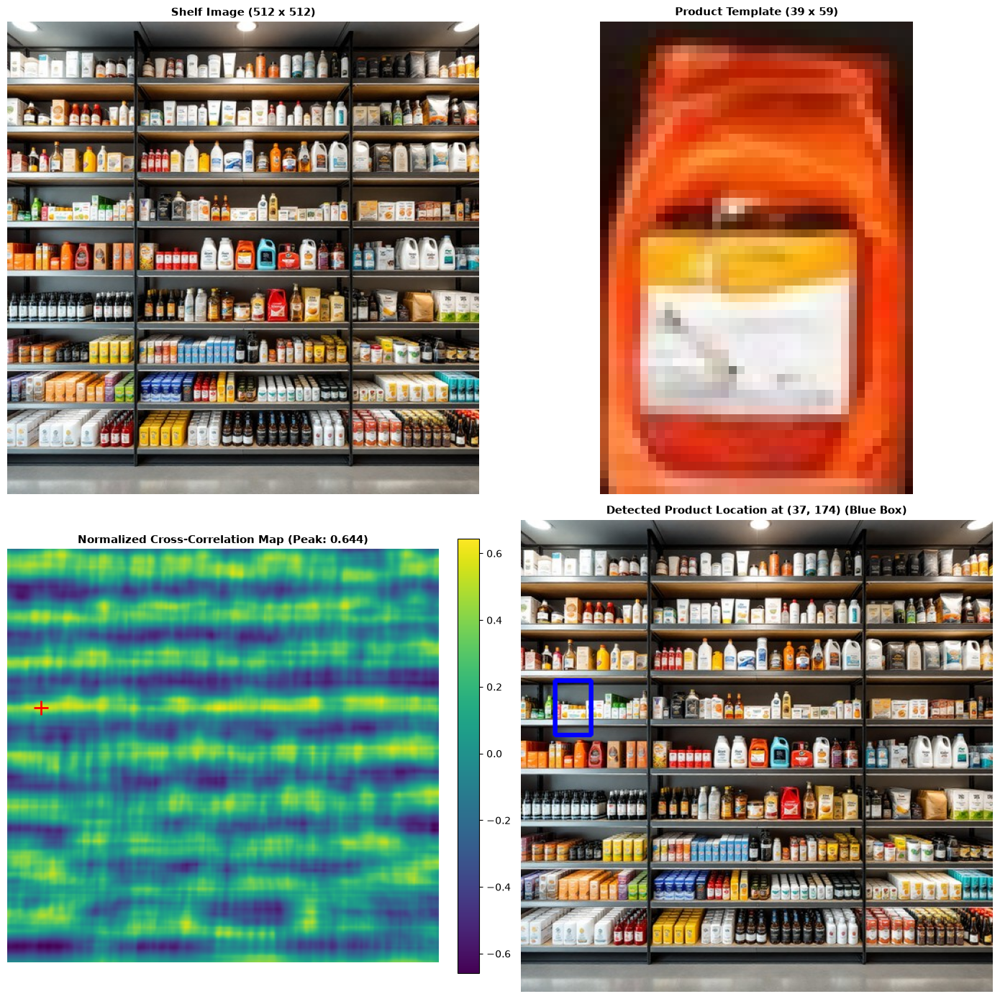

Product Template Dimensions: 39 x 59 (width x height)
Raw Cross-Correlation Peak Location: (43, 402)
Normalized Cross-Correlation Peak Location: (37, 174) with score: 0.6444


In [15]:
# Template matching on grocery shelf using cross-correlation
import os

shelf_candidates = [
    'images/organized-product-display-stockcake.jpg',
    'images/organised-product-display-stockcake.jpg',
    'images/shelf.jpg'
]
prod_candidates = [
    'images/product.png',
    'images/product.jpg',
    'images/template.jpg'
]

shelf_path = next(p for p in shelf_candidates if os.path.exists(p))
prod_path = next(p for p in prod_candidates if os.path.exists(p))

shelf_bgr = cv2.imread(shelf_path)
prod_bgr = cv2.imread(prod_path)

shelf_rgb = cv2.cvtColor(shelf_bgr, cv2.COLOR_BGR2RGB)
prod_rgb = cv2.cvtColor(prod_bgr, cv2.COLOR_BGR2RGB)

shelf_gray = cv2.cvtColor(shelf_bgr, cv2.COLOR_BGR2GRAY)
prod_gray = cv2.cvtColor(prod_bgr, cv2.COLOR_BGR2GRAY)

th, tw = prod_gray.shape

# Raw Cross-Correlation: R(x, y) = sum T * I
res_raw_ccorr = cv2.matchTemplate(shelf_gray, prod_gray, cv2.TM_CCORR)
_, _, _, max_loc_raw = cv2.minMaxLoc(res_raw_ccorr)

# Normalized Cross-Correlation (NCC): R_ncc(x, y) = sum (T - T_bar)(I - I_bar) / (sigma_T * sigma_I)
res_ncc = cv2.matchTemplate(shelf_gray, prod_gray, cv2.TM_CCOEFF_NORMED)
_, max_val_ncc, _, max_loc_ncc = cv2.minMaxLoc(res_ncc)

# Draw blue rectangle at detected location on RGB image
# Color in RGB: (0, 0, 255) for pure blue
shelf_detected_rgb = shelf_rgb.copy()
top_left = max_loc_ncc
bottom_right = (top_left[0] + tw, top_left[1] + th)
cv2.rectangle(shelf_detected_rgb, top_left, bottom_right, color=(0, 0, 255), thickness=3)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 14))

axes[0, 0].imshow(shelf_rgb)
axes[0, 0].set_title(f"Shelf Image ({shelf_rgb.shape[1]} x {shelf_rgb.shape[0]})", fontsize=11, fontweight="bold")
axes[0, 0].axis('off')

axes[0, 1].imshow(prod_rgb)
axes[0, 1].set_title(f"Product Template ({tw} x {th})", fontsize=11, fontweight="bold")
axes[0, 1].axis('off')

# Normalized cross-correlation response surface
im_corr = axes[1, 0].imshow(res_ncc, cmap='viridis')
axes[1, 0].plot(max_loc_ncc[0], max_loc_ncc[1], 'r+', markersize=14, markeredgewidth=2)
axes[1, 0].set_title(f"Normalized Cross-Correlation Map (Peak: {max_val_ncc:.3f})", fontsize=11, fontweight="bold")
axes[1, 0].axis('off')
plt.colorbar(im_corr, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Detected location marked with blue rectangle
axes[1, 1].imshow(shelf_detected_rgb)
axes[1, 1].set_title(f"Detected Product Location at {max_loc_ncc} (Blue Box)", fontsize=11, fontweight="bold")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"Product Template Dimensions: {tw} x {th} (width x height)")
print(f"Raw Cross-Correlation Peak Location: {max_loc_raw}")
print(f"Normalized Cross-Correlation Peak Location: {max_loc_ncc} with score: {max_val_ncc:.4f}")


### Observations on Template Matching via Cross-Correlation

- **Detected Product Location:** The target product template ($39 \times 59$ pixels) is successfully located on the middle shelf at top-left coordinate $(x=37, y=174)$ with a peak normalized correlation score of $\approx 0.644$. The blue bounding box accurately encloses the target item.
- **Raw Cross-Correlation vs. Normalized Cross-Correlation:**
  - **Raw Cross-Correlation ($\sum T \cdot I$):** Highly vulnerable to regional image luminance and energy. Bright background regions (such as illuminated white shelf surfaces at $(43, 402)$) produce high dot products regardless of pattern similarity, resulting in false positive detections.
  - **Normalized Cross-Correlation (NCC):** Subtracts the local mean and normalizes by the standard deviation of both the template and image patch. This eliminates illumination bias, enabling robust, accurate template detection based solely on structural pattern correlation.